# Sri Lankan Used Car Price Prediction (2026 market)
**Applied Machine Learning: Final Assignment.** Melanie Samaratunga (269188K), MSc in AI, University of Moratuwa

**Problem.** Sri Lanka reopened vehicle imports in 2025, and the used-car market has been repricing ever since. Buyers and sellers rely on guesswork when judging whether an asking price is fair. This project builds an **explainable model that estimates a fair asking price** from a car's listing details. Every estimate comes with a SHAP explanation.

**Data.** Car adverts from **Riyasewana.com**, Sri Lanka's largest vehicle classified site, posted **May – August 2026**. Prices are in Sri Lankan rupees.
* Source: scraped listings published by S. Savindu in the [Sri-Lanka-Car-Market-Analysis-2026](https://github.com/savindu777/Sri-Lanka-Car-Market-Anlaysis-2026) repository (MIT licence, as stated in its README).
* Only the **raw per-model CSV files** are used. All cleaning, analysis and modelling in this notebook is my own.
* The cleaning code (`data_prep.py`) works on any freshly scraped file with the same columns.

**Pipeline.**
1. Data quality audit and cleaning
2. EDA
3. Leakage-safe split
4. Baselines
5. Tuned model comparison: Ridge, RF, XGBoost, LightGBM, CatBoost, Stacking
6. Held-out evaluation and error analysis
7. SHAP and LIME
8. Export for the Streamlit app

In [1]:
import warnings, json, os, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost_wrapper import CatBoostReg   # sklearn-compatible wrapper (see catboost_wrapper.py)
from data_prep import load_raw, clean

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
FIG = "reports/figures"; os.makedirs(FIG, exist_ok=True); os.makedirs("models", exist_ok=True)

## 1. Data understanding and quality audit

In [2]:
raw = load_raw("data/raw")
print(raw.shape, "from", raw["source_file"].nunique(), "files")
raw.head(3).T

(6436, 22) from 30 files


,0,1,2
Brand,Audi,Audi,Audi
Model,A3 Sline,A1 Sline,A1 Highest Spec
YOM,2018,2017,2016
Mileage,"93,000 km","96,000 km","86,000 km"
Gear,Automatic,Automatic,Automatic
Fuel Type,Petrol,Petrol,Petrol
Engine (cc),1000.0,990.0,10000.0
Condition,Registered (Used),Registered (Used),Registered (Used)
Ad Date,"2026 Jun 05, 11:39 am","2026 Jun 06, 10:27 pm","2026 Jul 19, 9:58 am"
Location,Colombo,Kandy,Colombo


In [3]:
print("Missing values in raw data:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nPrice field, top values:", raw["Price"].value_counts().head(3).to_dict())
print("Engine (cc) range:", raw["Engine (cc)"].min(), "to", raw["Engine (cc)"].max())

Missing values in raw data:
Mileage                  18
Engine (cc)             178
Number of Cylinders     218
Power Shutters          218
Power Mirrors           218
Number of Cylinder     6218
Power Shutter          6218
Power Mirror           6218
dtype: int64

Price field, top values: {'Negotiable': 1440, 'Rs. 5500000': 35, 'Rs. 11500000': 34}
Engine (cc) range: 1.0 to 149000.0


**Problems found in the raw data**

| # | Problem | Fix |
|---|---|---|
| 1 | Two column spellings (`Power Mirror` vs `Power Mirrors`, etc.): one source file used singular headers | Merge |
| 2 | 22% of adverts say **"Negotiable"** instead of a price | Remove (no target) |
| 3 | Engine cc typing errors: 1 (litres), 18, 130, 15,000, 149,000 | Rescale to the plausible range 600–7,000 cc |
| 4 | Prices like Rs 3,450 or a 2018 CR-V at Rs 1.45M (deposits or lease instalments) | Remove prices < Rs 300k, and prices > 4× away from similar cars |
| 5 | Used cars older than 2 years with < 1,000 km | Typo, so mileage set to missing (imputed) |
| 6 | Free-text model names (900+ spellings) | Derive a **model family** (e.g. TOYOTA AQUA) |
| 7 | Antique cars | Remove (separate collector market) |
| 8 | The same car re-posted | Grouped split (see §3) |

In [4]:
df, audit = clean(raw, ref_year=2026)
for k, v in audit.items():
    if k != "peer_outlier_examples":
        print(f"{k:32s} {v}")
print("\nExamples of removed price outliers:")
display(pd.DataFrame(audit["peer_outlier_examples"]))
json.dump({k: v for k, v in audit.items() if k != "peer_outlier_examples"}, open("reports/cleaning_audit.json", "w"), indent=1)
df.head()

raw_rows                         6436
merged_Number of Cylinder        218
merged_Power Shutter             218
merged_Power Mirror              218
dup_url_removed                  1
negotiable_removed               1440
engine_corrected                 69
engine_set_missing               0
antique_removed                  6
rare_families_grouped            175
mileage_set_missing              45
price_too_low_removed            3
price_peer_outliers_removed      13
final_rows                       4973
repost_rows                      85

Examples of removed price outliers:


,Brand,Model,YOM,Price_Rs
0,AUDI,A6 RS6,2012,3250000.0
1,BMW,318I,2018,1950000.0
2,BMW,320i,2011,2200000.0
3,BMW,740LI,2010,1000000.0
4,HONDA,CRV,2018,1450000.0
5,HONDA,Crv,2019,1880000.0
6,HONDA,CRV,2018,3000000.0
7,MAZDA,3,2013,1050000.0


,Brand,Family,Model,YOM,Age,Mileage_km,Engine_cc,Cylinders,Gear,Fuel,...,Country,Location,PowerSteering,PowerShutters,PowerMirrors,Ad_Date,URL,Price_Rs,Price_mn,listing_group
0,AUDI,AUDI A3,A3 Sline,2018,8,93000.0,1000.0,3.0,Automatic,Petrol,...,Germany,Colombo,1,1,1,2026-06-05,https://riyasewana.com/buy/audi-3-s-line-sale-...,14400000.0,14.40,0
1,AUDI,AUDI A1,A1 Sline,2017,9,96000.0,990.0,3.0,Automatic,Petrol,...,Germany,Kandy,1,1,1,2026-06-06,https://riyasewana.com/buy/audi-a1-1-0-sale-ka...,8650000.0,8.65,1
2,AUDI,AUDI A1,A1 Highest Spec,2016,10,86000.0,1000.0,6.0,Automatic,Petrol,...,Germany,Colombo,1,1,1,2026-07-19,https://riyasewana.com/buy/audi-a1-highest-sal...,8200000.0,8.20,2
3,AUDI,AUDI A1,A1,2017,9,69000.0,1000.0,3.0,Automatic,Petrol,...,Germany,Bandaragama,1,1,1,2026-07-27,https://riyasewana.com/buy/audi-a1-sale-bandar...,8700000.0,8.70,3
4,AUDI,AUDI A1,A1,2016,10,55000.0,1000.0,3.0,Automatic,Petrol,...,Germany,Bandaragama,1,1,1,2026-07-28,https://riyasewana.com/buy/audi-a1-sale-bandar...,9500000.0,9.50,4


**Mileage is real in this dataset.** Within the same manufacture year, mileage varies widely. (In the widely used Kaggle Sri Lankan car dataset, mileage is a fixed formula of year.) This lets the model learn the true effect of usage separately from age.

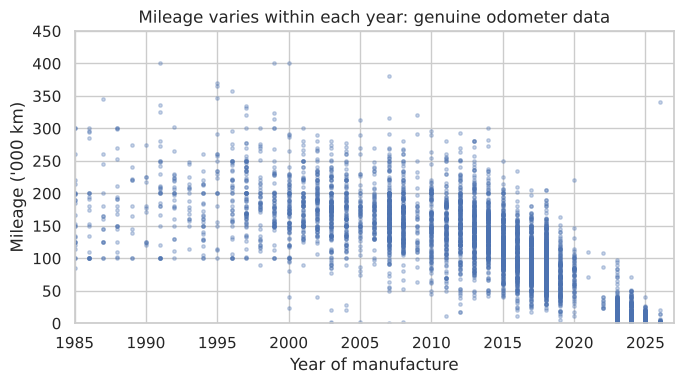

Distinct mileage values per year (median): 36.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["YOM"], df["Mileage_km"] / 1000, s=6, alpha=0.3)
ax.set(xlabel="Year of manufacture", ylabel="Mileage ('000 km)", title="Mileage varies within each year: genuine odometer data", xlim=(1985, 2027), ylim=(0, 450))
plt.tight_layout(); plt.savefig(f"{FIG}/01_mileage_real.png", dpi=150); plt.show()
print("Distinct mileage values per year (median):", df.groupby("YOM")["Mileage_km"].nunique().median())

## 2. Exploratory data analysis

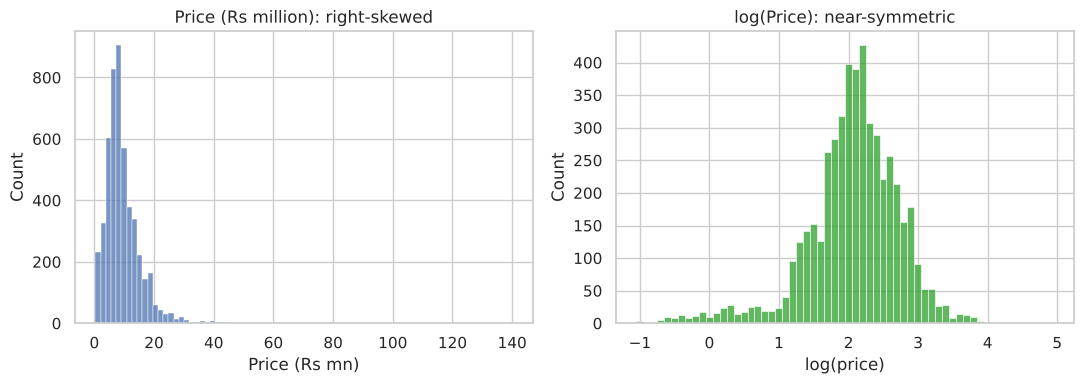

count    4973.00
mean        9.54
std         6.32
min         0.35
1%          0.79
25%         5.75
50%         8.25
75%        11.98
99%        31.00
max       140.00
Name: Price_mn, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Price_mn"], bins=80, ax=axes[0]); axes[0].set(title="Price (Rs million): right-skewed", xlabel="Price (Rs mn)")
sns.histplot(np.log(df["Price_mn"]), bins=60, ax=axes[1], color="tab:green"); axes[1].set(title="log(Price): near-symmetric", xlabel="log(price)")
plt.tight_layout(); plt.savefig(f"{FIG}/02_price_distribution.png", dpi=150); plt.show()
print(df["Price_mn"].describe(percentiles=[.01, .25, .5, .75, .99]).round(2))

Prices range from Rs 0.35M to Rs 140M, so we model **log(price)**. This makes effects proportional (one extra year costs about x%) and stops a few luxury cars from dominating the loss.

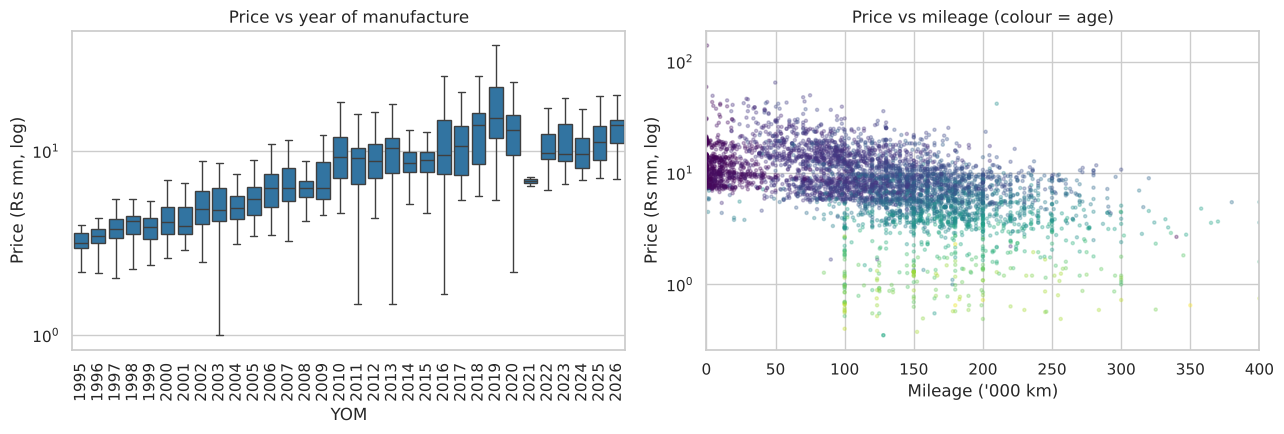

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sub = df[df["YOM"] >= 1995]
sns.boxplot(data=sub, x="YOM", y="Price_mn", ax=axes[0], showfliers=False, color="tab:blue")
axes[0].set_yscale("log"); axes[0].set(title="Price vs year of manufacture", ylabel="Price (Rs mn, log)"); axes[0].tick_params(axis="x", rotation=90)
axes[1].scatter(df["Mileage_km"] / 1000, df["Price_mn"], s=5, alpha=0.3, c=df["Age"], cmap="viridis")
axes[1].set(yscale="log", xlim=(0, 400), title="Price vs mileage (colour = age)", xlabel="Mileage ('000 km)", ylabel="Price (Rs mn, log)")
plt.tight_layout(); plt.savefig(f"{FIG}/03_price_vs_age_mileage.png", dpi=150); plt.show()

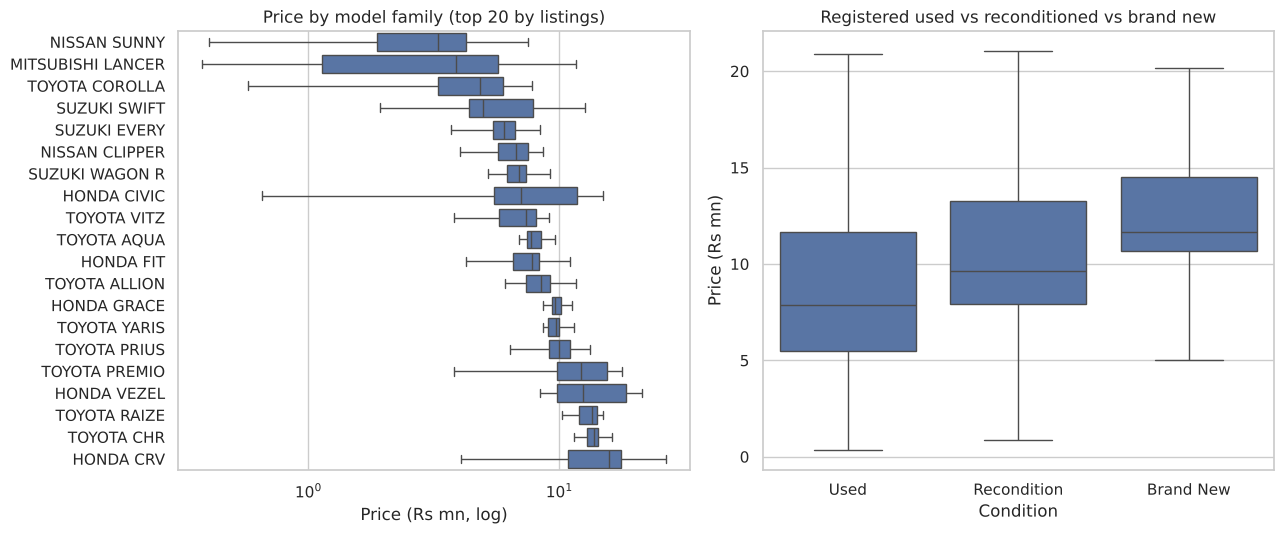

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order = df.groupby("Family")["Price_mn"].median().sort_values()
top = df["Family"].value_counts().head(20).index
o = order[order.index.isin(top)].index
sns.boxplot(data=df[df.Family.isin(top)], y="Family", x="Price_mn", order=o, showfliers=False, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set(title="Price by model family (top 20 by listings)", xlabel="Price (Rs mn, log)", ylabel="")
sns.boxplot(data=df, x="Condition", y="Price_mn", showfliers=False, ax=axes[1], order=["Used", "Recondition", "Brand New"])
axes[1].set(title="Registered used vs reconditioned vs brand new", ylabel="Price (Rs mn)")
plt.tight_layout(); plt.savefig(f"{FIG}/04_family_condition.png", dpi=150); plt.show()

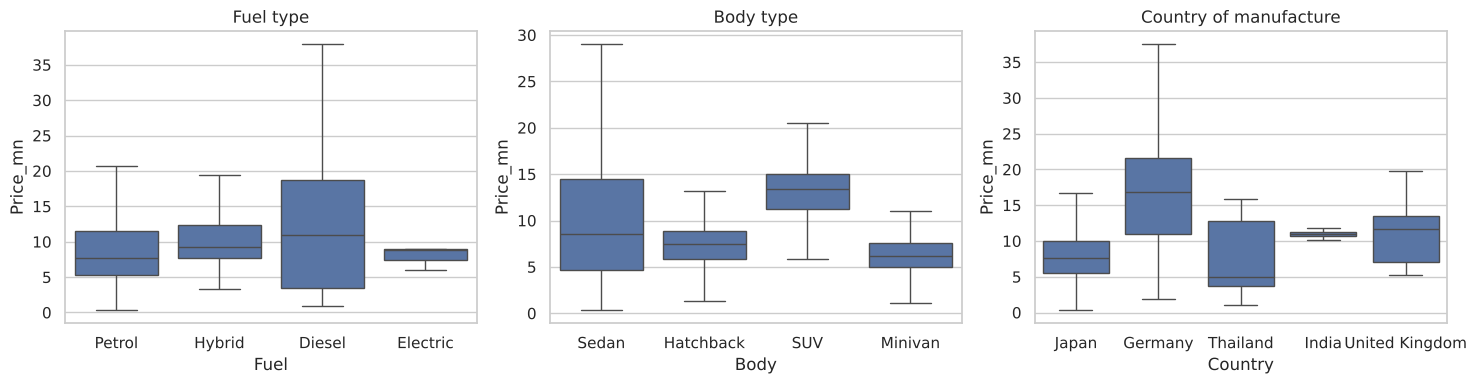

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Fuel", y="Price_mn", showfliers=False, ax=axes[0]); axes[0].set(title="Fuel type")
sns.boxplot(data=df, x="Body", y="Price_mn", showfliers=False, ax=axes[1]); axes[1].set(title="Body type")
sns.boxplot(data=df, x="Country", y="Price_mn", showfliers=False, ax=axes[2], order=df.Country.value_counts().index[:5]); axes[2].set(title="Country of manufacture")
plt.tight_layout(); plt.savefig(f"{FIG}/05_fuel_body_country.png", dpi=150); plt.show()

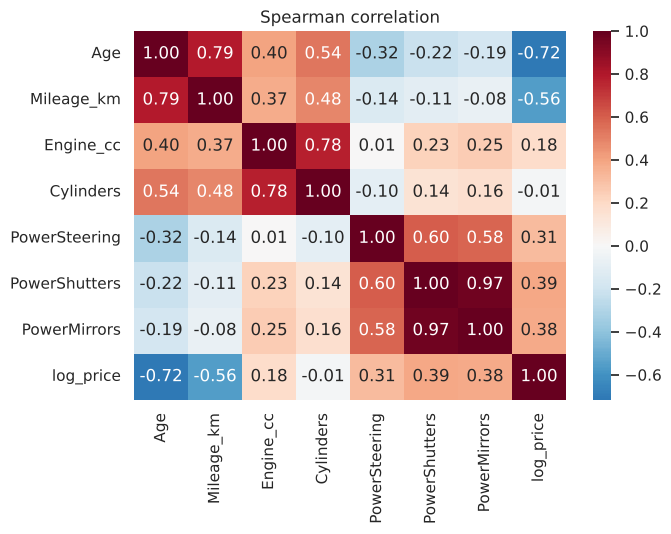

In [10]:
num = df[["Price_mn", "Age", "Mileage_km", "Engine_cc", "Cylinders", "PowerSteering", "PowerShutters", "PowerMirrors"]].copy()
num["log_price"] = np.log(num.pop("Price_mn"))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax); ax.set_title("Spearman correlation")
plt.tight_layout(); plt.savefig(f"{FIG}/06_correlation.png", dpi=150); plt.show()

**EDA takeaways**
* **Age** and **mileage** both lower price, and they are correlated but not identical. A low-mileage older car keeps more value.
* **Model family** separates the market strongly. Kei cars (Every, Clipper, Wagon R) sit at the bottom; Mercedes/BMW and newer SUVs (CHR, Vezel, CR-V) sit at the top.
* **Reconditioned** (imported, never registered locally) cars cost more than registered used cars of similar spec. This is a Sri Lanka-specific effect.
* **Hybrids** carry a premium, which reflects local fuel prices and import-tax structure.

**Sample caveat:** the data covers 11 brands and about 30 popular model families, as chosen by the scraper's author. It represents the mainstream market, not every car in Sri Lanka.

## 3. Leakage-safe train/test split
* Re-posted adverts (same car, same price and mileage) are grouped together, so a car can never be in both training and test data.
* 80/20 grouped split, with the test set used **only once** at the end.
* Tuning uses 5-fold **GroupKFold** on the training data.

In [11]:
FEATURES = ["Brand", "Family", "Age", "Mileage_km", "Engine_cc", "Cylinders", "Gear", "Fuel", "Body", "Condition",
            "Country", "Location", "PowerSteering", "PowerShutters", "PowerMirrors"]
CAT_HIGH = ["Brand", "Family", "Location"]                     # many levels -> target encoding
CAT_LOW = ["Gear", "Fuel", "Body", "Condition", "Country"]     # few levels  -> one-hot
NUM = ["Age", "Mileage_km", "Engine_cc", "Cylinders", "PowerSteering", "PowerShutters", "PowerMirrors"]

X, y, groups = df[FEATURES], df["Price_mn"], df["listing_group"]
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
g_train = groups.iloc[tr_idx]
print("Train:", X_train.shape, "Test:", X_test.shape, "| group overlap:", len(set(g_train) & set(groups.iloc[te_idx])))
cv = GroupKFold(n_splits=5)

Train: (3976, 15) Test: (997, 15) | group overlap: 0


**Preprocessing (fitted inside every CV fold, so no leakage):**
* Median imputation for the few missing numeric values (mileage, engine).
* `TargetEncoder` with internal cross-fitting for Brand, Family and Location.
* One-hot encoding for the low-cardinality categories.
* Every model learns `log(price)` through `TransformedTargetRegressor`, and predictions come back in Rs million.

In [12]:
def make_pre(scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("te", TargetEncoder(target_type="continuous", random_state=SEED), CAT_HIGH),
        ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), CAT_LOW),
        ("num", Pipeline(num_steps), NUM),
    ], verbose_feature_names_out=False)

def logged(model):
    return TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)

def pipe(model, scale=False):
    return logged(Pipeline([("pre", make_pre(scale)), ("model", model)]))

def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred), "MAE_mn": mean_absolute_error(y_true, y_pred),
            "RMSE_mn": mean_squared_error(y_true, y_pred) ** 0.5, "MAPE_%": 100 * mean_absolute_percentage_error(y_true, y_pred),
            "R2_log": r2_score(np.log(y_true), np.log(np.clip(y_pred, 1e-3, None)))}

SCORING = {"r2": "r2", "mae": "neg_mean_absolute_error"}
results, cv_rows = {}, []
def add_cv(name, r2, sd, mae):
    cv_rows.append({"model": name, "CV_R2": r2, "CV_R2_sd": sd, "CV_MAE_mn": mae})

## 4. Baselines
1. **Global median:** the same price for every car.
2. **"Existing approach":** the median asking price of the same model family and year, falling back to family, then brand. This mimics a buyer scrolling through Riyasewana to compare similar ads.
3. **Ridge regression:** a linear model on log-price.

In [13]:
class PeerMedianBaseline:
    def fit(self, X, y):
        d = X.assign(y=y.values)
        self.levels = [["Family", "Age"], ["Family"], ["Brand"]]
        self.tables = [d.groupby(l)["y"].median() for l in self.levels]
        self.glob = d["y"].median(); return self
    def predict(self, X):
        out = pd.Series(np.nan, index=X.index)
        for l, t in zip(self.levels, self.tables):
            key = pd.MultiIndex.from_frame(X[l]) if len(l) > 1 else X[l[0]]
            out = out.fillna(pd.Series(t.reindex(key).values, index=X.index))
        return out.fillna(self.glob).values

results["Baseline: global median"] = metrics(y_test, DummyRegressor(strategy="median").fit(X_train, y_train).predict(X_test))
results["Baseline: peer median (family+age)"] = metrics(y_test, PeerMedianBaseline().fit(X_train, y_train).predict(X_test))

ridge = pipe(Ridge(alpha=1.0), scale=True)
r = cross_validate(ridge, X_train, y_train, groups=g_train, cv=cv, scoring=SCORING)
add_cv("Ridge", r["test_r2"].mean(), r["test_r2"].std(), -r["test_mae"].mean())
results["Ridge (linear)"] = metrics(y_test, ridge.fit(X_train, y_train).predict(X_test))
pd.DataFrame(results).T.round(3)

,R2,MAE_mn,RMSE_mn,MAPE_%,R2_log
Baseline: global median,-0.054,4.380,6.550,73.753,-0.004
Baseline: peer median (family+age),0.848,1.004,2.489,13.704,0.885
Ridge (linear),0.825,1.410,2.670,14.201,0.917


## 5. Tuned model comparison
Each model is tuned with `RandomizedSearchCV` (5-fold GroupKFold, optimising R²). Random Forest is also run with default settings, to show what tuning adds.

In [14]:
def tune(name, model, grid, n_iter=15, prefix="regressor__model__", estimator=None):
    t0 = time.time()
    search = RandomizedSearchCV(estimator or pipe(model), {f"{prefix}{k}": v for k, v in grid.items()}, n_iter=n_iter, cv=cv,
                                scoring=SCORING, refit="r2", random_state=SEED, n_jobs=-1 if estimator is None else 1)
    search.fit(X_train, y_train, groups=g_train)
    i = search.best_index_; cr = search.cv_results_
    add_cv(name, cr["mean_test_r2"][i], cr["std_test_r2"][i], -cr["mean_test_mae"][i])
    best = {k.replace(prefix, ""): v for k, v in search.best_params_.items()}
    print(f"{name}: CV R2={cr['mean_test_r2'][i]:.4f}  ({time.time()-t0:.0f}s)\n  best params: {best}")
    return search.best_estimator_, best

rf_default = pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1))
r = cross_validate(rf_default, X_train, y_train, groups=g_train, cv=cv, scoring=SCORING)
add_cv("Random Forest (default)", r["test_r2"].mean(), r["test_r2"].std(), -r["test_mae"].mean())
results["Random Forest (default)"] = metrics(y_test, rf_default.fit(X_train, y_train).predict(X_test))

best_models, best_params = {}, {}
best_models["Random Forest (tuned)"], best_params["Random Forest (tuned)"] = tune("Random Forest (tuned)",
    RandomForestRegressor(random_state=SEED, n_jobs=1),
    {"n_estimators": [200, 300, 500], "max_depth": [None, 15, 25], "min_samples_leaf": [1, 2, 3, 5], "max_features": [0.4, 0.6, 0.8, 1.0]}, n_iter=12)

best_models["XGBoost"], best_params["XGBoost"] = tune("XGBoost",
    XGBRegressor(random_state=SEED, n_jobs=1, tree_method="hist"),
    {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6, 8], "subsample": [0.7, 0.85, 1.0],
     "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5], "reg_lambda": [0.5, 1, 3]})

best_models["LightGBM"], best_params["LightGBM"] = tune("LightGBM",
    LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
    {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [15, 31, 63], "min_child_samples": [5, 10, 20],
     "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1], "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [0, 1, 3]})

Random Forest (tuned): CV R2=0.8647  (52s)
  best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': None}


XGBoost: CV R2=0.8828  (18s)
  best params: {'subsample': 0.7, 'reg_lambda': 3, 'n_estimators': 900, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


LightGBM: CV R2=0.8801  (18s)
  best params: {'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 1, 'num_leaves': 31, 'n_estimators': 600, 'min_child_samples': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


**CatBoost** handles categorical features natively with ordered target statistics, so it receives the raw categories without our encoders.

In [15]:
CB_CATS = CAT_HIGH + CAT_LOW
best_models["CatBoost"], best_params["CatBoost"] = tune("CatBoost", None,
    {"iterations": [600, 1000], "learning_rate": [0.03, 0.06, 0.1], "depth": [4, 6, 8], "l2_leaf_reg": [1, 3, 6]},
    n_iter=8, prefix="regressor__", estimator=logged(CatBoostReg(cat_features=CB_CATS, random_seed=SEED, thread_count=-1)))

CatBoost: CV R2=0.8845  (172s)
  best params: {'learning_rate': 0.1, 'l2_leaf_reg': 6, 'iterations': 1000, 'depth': 4}


**Stacking:** a Ridge meta-learner over the tuned RF, XGBoost and LightGBM.

In [16]:
stack = logged(StackingRegressor(estimators=[("rf", best_models["Random Forest (tuned)"].regressor_),
                                             ("xgb", best_models["XGBoost"].regressor_), ("lgbm", best_models["LightGBM"].regressor_)],
                                 final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=1))
r = cross_validate(stack, X_train, y_train, groups=g_train, cv=cv, scoring=SCORING)
add_cv("Stacking (RF+XGB+LGBM)", r["test_r2"].mean(), r["test_r2"].std(), -r["test_mae"].mean())
best_models["Stacking (RF+XGB+LGBM)"] = stack.fit(X_train, y_train)

## 6. Held-out test evaluation

In [17]:
for name, m in best_models.items():
    results[name] = metrics(y_test, m.predict(X_test))
res = pd.DataFrame(results).T.sort_values("R2", ascending=False)
cv_df = pd.DataFrame(cv_rows).set_index("model").sort_values("CV_R2", ascending=False)
print("Cross-validation on training set (5-fold GroupKFold):"); display(cv_df.round(4))
print("Held-out test set (MAE/RMSE in Rs million):"); display(res.round(3))
res.round(4).to_csv("reports/test_results.csv"); cv_df.round(4).to_csv("reports/cv_results.csv")

Cross-validation on training set (5-fold GroupKFold):


,CV_R2,CV_R2_sd,CV_MAE_mn
model,,,
CatBoost,0.8845,0.0497,0.8296
XGBoost,0.8828,0.0735,0.7829
LightGBM,0.8801,0.0810,0.8008
Random Forest (tuned),0.8647,0.1011,0.7647
Random Forest (default),0.8601,0.1061,0.7894
Stacking (RF+XGB+LGBM),0.8273,0.0671,1.2716
Ridge,0.7759,0.0569,1.3791


Held-out test set (MAE/RMSE in Rs million):


,R2,MAE_mn,RMSE_mn,MAPE_%,R2_log
LightGBM,0.940,0.787,1.561,8.792,0.957
Random Forest (tuned),0.937,0.759,1.603,8.475,0.960
Random Forest (default),0.934,0.791,1.640,8.876,0.956
XGBoost,0.932,0.796,1.669,8.843,0.953
CatBoost,0.929,0.849,1.706,8.882,0.957
Stacking (RF+XGB+LGBM),0.912,1.125,1.895,12.065,0.944
Baseline: peer median (family+age),0.848,1.004,2.489,13.704,0.885
Ridge (linear),0.825,1.410,2.670,14.201,0.917
Baseline: global median,-0.054,4.380,6.550,73.753,-0.004


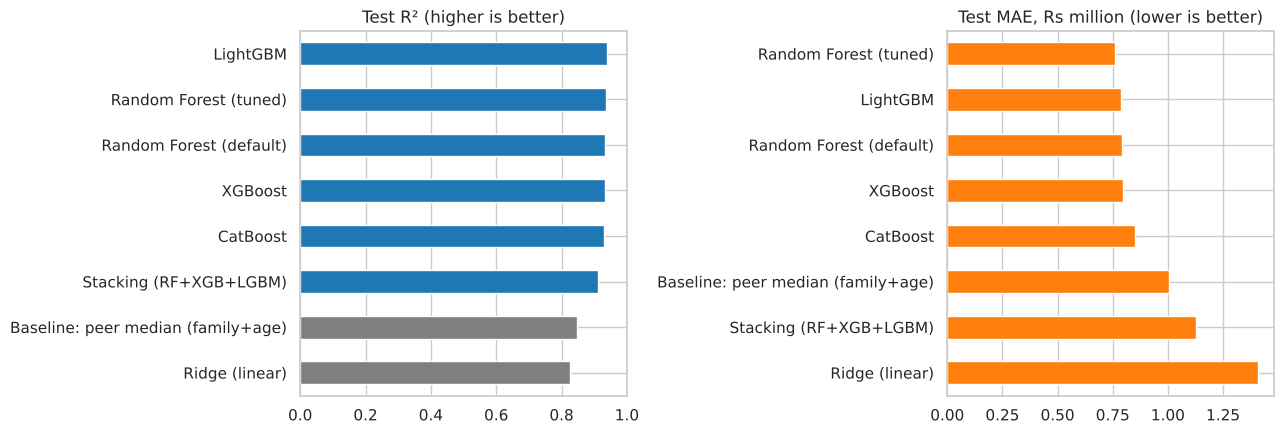

In [18]:
plot_res = res.drop(index="Baseline: global median")
colors = ["tab:gray" if ("Baseline" in i or "Ridge" in i) else "tab:blue" for i in plot_res["R2"].sort_values().index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_res["R2"].sort_values().plot.barh(ax=axes[0], color=colors); axes[0].set(title="Test R² (higher is better)", xlim=(0, 1))
plot_res["MAE_mn"].sort_values(ascending=False).plot.barh(ax=axes[1], color="tab:orange"); axes[1].set(title="Test MAE, Rs million (lower is better)")
plt.tight_layout(); plt.savefig(f"{FIG}/07_model_comparison.png", dpi=150); plt.show()

### Choosing the deployed model
The deployed model is chosen on **cross-validated R²**, not the test set, which keeps the test score honest. We choose among single models, because they are explainable with exact TreeSHAP and small enough to deploy. If the stack only matches its best member, it adds complexity without benefit.

Deployed model: CatBoost


,R2,MAE_mn,RMSE_mn,MAPE_%,R2_log
CatBoost,0.9285,0.8493,1.7059,8.8815,0.9574
Stacking (RF+XGB+LGBM),0.9118,1.1255,1.8947,12.0648,0.9444


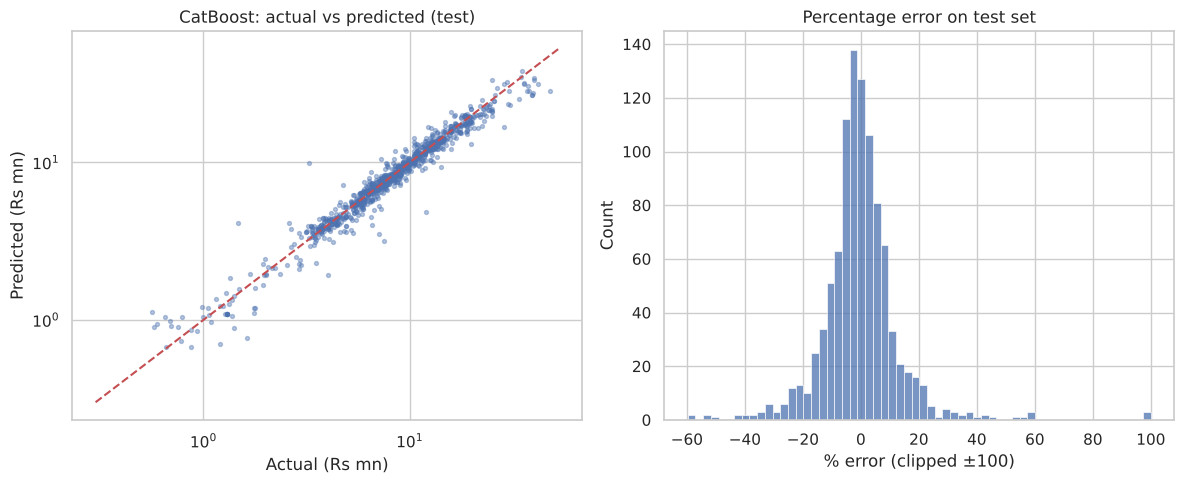

Within ±10%: 71.5%   within ±20%: 90.6%   median abs error: 5.5%


In [19]:
single = ["CatBoost", "LightGBM", "XGBoost", "Random Forest (tuned)"]
chosen = max(single, key=lambda n: cv_df.loc[n, "CV_R2"])
print("Deployed model:", chosen); display(res.loc[[chosen, "Stacking (RF+XGB+LGBM)"]].round(4))
final = best_models[chosen]
y_pred = final.predict(X_test)
err = (y_pred - y_test) / y_test * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.4); lim = [0.3, y_test.max() * 1.1]
axes[0].plot(lim, lim, "r--"); axes[0].set(xscale="log", yscale="log", xlabel="Actual (Rs mn)", ylabel="Predicted (Rs mn)", title=f"{chosen}: actual vs predicted (test)")
sns.histplot(err.clip(-100, 100), bins=60, ax=axes[1]); axes[1].set(title="Percentage error on test set", xlabel="% error (clipped ±100)")
plt.tight_layout(); plt.savefig(f"{FIG}/08_actual_vs_pred.png", dpi=150); plt.show()
print(f"Within ±10%: {(err.abs() <= 10).mean():.1%}   within ±20%: {(err.abs() <= 20).mean():.1%}   median abs error: {err.abs().median():.1f}%")

### Error analysis

In [20]:
te = X_test.assign(actual=y_test.values, pred=y_pred, abs_pct_err=np.abs(err.values))
te["price_band"] = pd.cut(te["actual"], [0, 4, 8, 12, 20, 200], labels=["<4M", "4-8M", "8-12M", "12-20M", "20M+"])
display(te.groupby("price_band", observed=True)["abs_pct_err"].agg(["count", "median", "mean"]).round(1))
display(te.groupby("Condition")["abs_pct_err"].agg(["count", "median"]).round(1))
display(te.sort_values("abs_pct_err", ascending=False).head(8)[["Family", "Age", "Mileage_km", "Condition", "actual", "pred", "abs_pct_err"]].round(1))

,count,median,mean
price_band,,,
<4M,130,10.2,17.5
4-8M,349,5.4,7.7
8-12M,256,4.4,6.5
12-20M,208,4.8,7.0
20M+,54,12.2,14.7


,count,median
Condition,,
Brand New,31,2.6
Recondition,70,4.0
Used,896,5.8


,Family,Age,Mileage_km,Condition,actual,pred,abs_pct_err
1638,MERCEDES-BENZ C200,19,158000.0,Used,3.2,10.0,206.4
2408,NISSAN CLIPPER,13,NaN,Used,1.5,4.1,179.1
2067,MITSUBISHI LANCER,45,245000.0,Used,0.6,1.1,97.7
2113,MITSUBISHI LANCER,45,123456.0,Used,0.6,1.0,60.0
1936,MITSUBISHI OTHER,24,157000.0,Used,12.0,4.8,59.7
1827,MERCEDES-BENZ OTHER,34,178000.0,Used,2.6,4.1,59.3
2438,NISSAN SUNNY,42,325000.0,Used,0.6,0.9,59.1
1816,MERCEDES-BENZ OTHER,33,115000.0,Used,7.5,3.2,57.6


## 7. Explainability: SHAP

SHAP values are in log-price units: +0.10 ≈ +10.5% on price


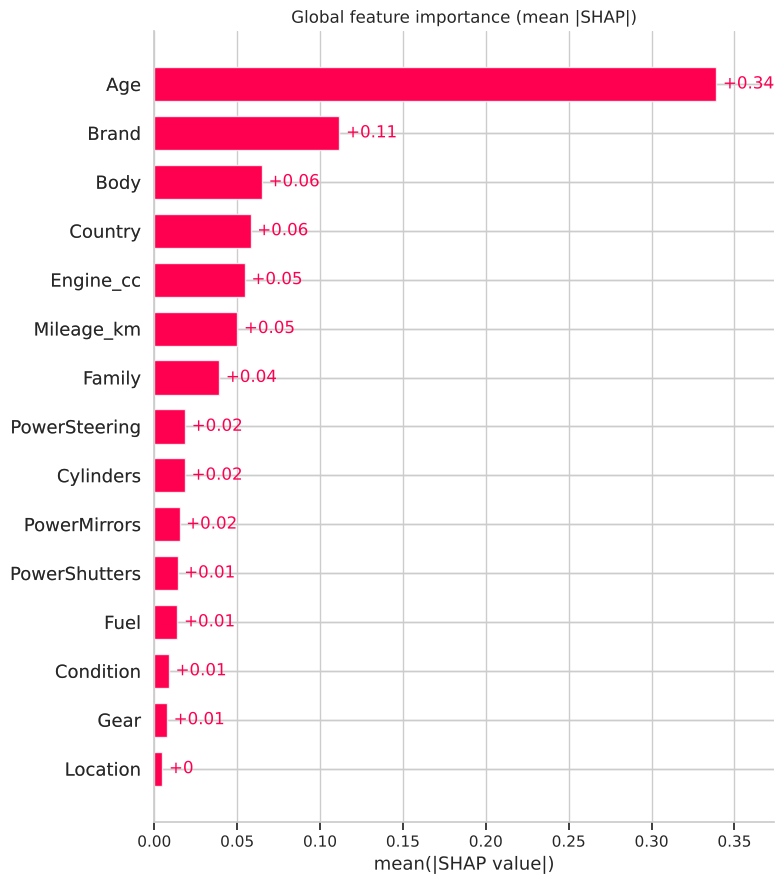

In [21]:
import shap
if chosen == "CatBoost":
    X_shap = X_test.copy(); explainer = shap.TreeExplainer(final.regressor_.model_)
else:
    p = final.regressor_
    X_shap = pd.DataFrame(p.named_steps["pre"].transform(X_test), columns=p.named_steps["pre"].get_feature_names_out(), index=X_test.index)
    explainer = shap.TreeExplainer(p.named_steps["model"])
sv = explainer(X_shap)
print("SHAP values are in log-price units: +0.10 ≈ +10.5% on price")
plt.figure(); shap.plots.bar(sv, max_display=15, show=False); plt.title("Global feature importance (mean |SHAP|)")
plt.tight_layout(); plt.savefig(f"{FIG}/09_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

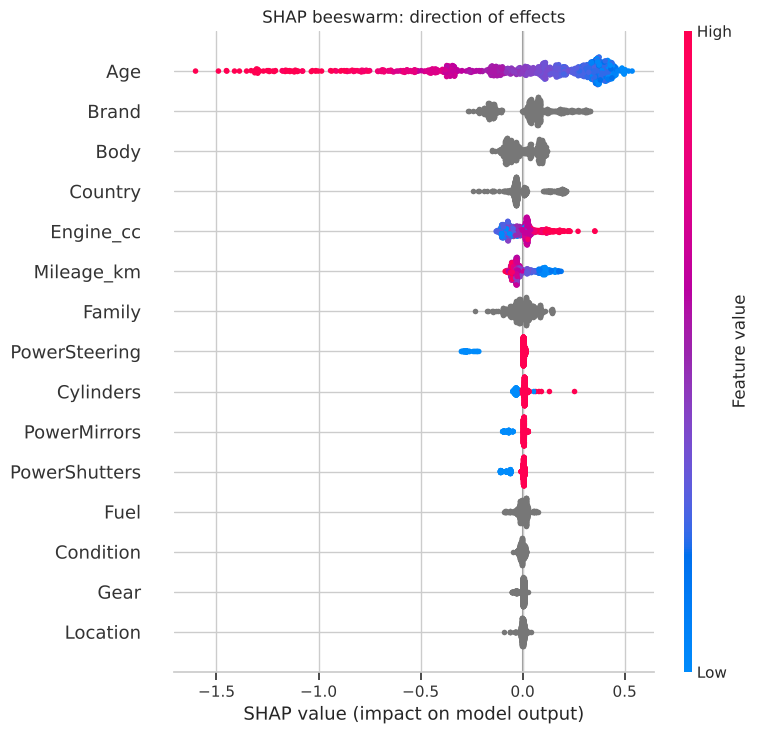

In [22]:
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.title("SHAP beeswarm: direction of effects")
plt.tight_layout(); plt.savefig(f"{FIG}/10_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

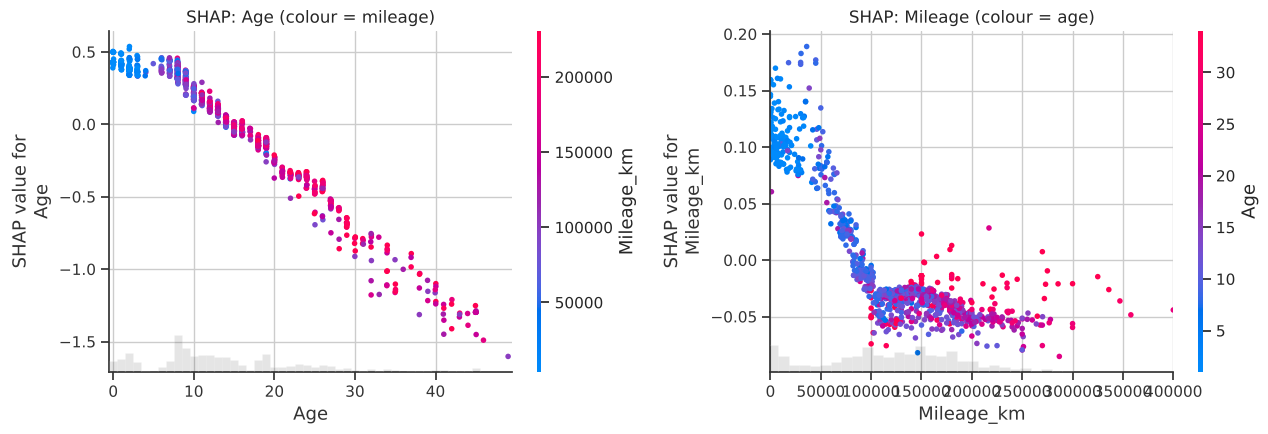

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shap.plots.scatter(sv[:, "Age"], color=sv[:, "Mileage_km"], ax=axes[0], show=False); axes[0].set_title("SHAP: Age (colour = mileage)")
shap.plots.scatter(sv[:, "Mileage_km"], color=sv[:, "Age"], ax=axes[1], show=False); axes[1].set_title("SHAP: Mileage (colour = age)")
axes[1].set_xlim(0, 400000)
plt.tight_layout(); plt.savefig(f"{FIG}/11_shap_age_mileage.png", dpi=150, bbox_inches="tight"); plt.show()

### Local explanation of one test car

{'Brand': 'MITSUBISHI', 'Family': 'MITSUBISHI LANCER', 'Age': 24, 'Mileage_km': 150000.0, 'Engine_cc': 1500.0, 'Cylinders': 4.0, 'Gear': 'Automatic', 'Fuel': 'Petrol', 'Body': 'Sedan', 'Condition': 'Used', 'Country': 'Japan', 'Location': 'Kolonnawa', 'PowerSteering': 1, 'PowerShutters': 1, 'PowerMirrors': 1}
Actual: Rs 5.50M  |  Predicted: Rs 5.20M


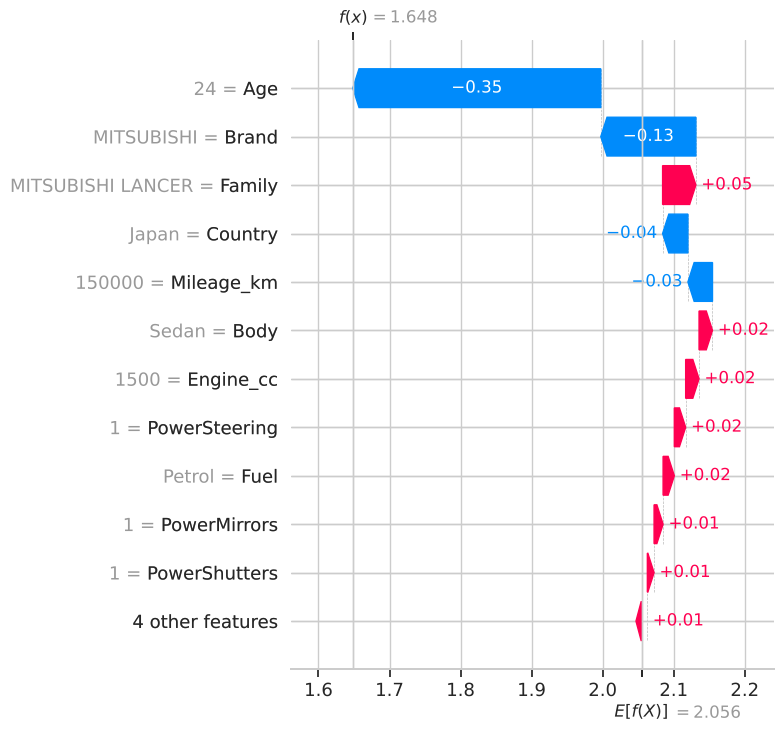

In [24]:
pos = int(np.argsort(np.abs(err.values))[len(err) // 2])   # a car with typical (median) error
print(X_test.iloc[pos].to_dict()); print(f"Actual: Rs {y_test.iloc[pos]:.2f}M  |  Predicted: Rs {y_pred[pos]:.2f}M")
plt.figure(); shap.plots.waterfall(sv[pos], max_display=12, show=False)
plt.tight_layout(); plt.savefig(f"{FIG}/12_shap_waterfall.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Explainability: LIME
LIME explains one prediction by fitting a small linear model to perturbed copies of the car. Here we explain the same car as the SHAP waterfall.

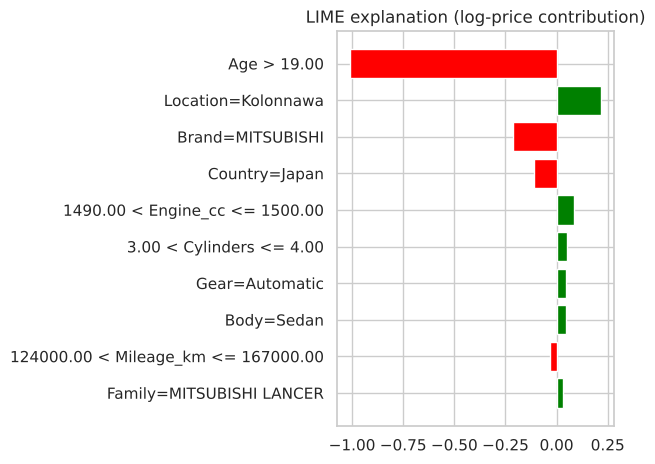

LIME surrogate local R²: 0.629


[('Age > 19.00', -1.0111153716987662),
 ('Location=Kolonnawa', 0.2192261854972837),
 ('Brand=MITSUBISHI', -0.2142371386904949),
 ('Country=Japan', -0.11251697970314654),
 ('1490.00 < Engine_cc <= 1500.00', 0.08566997907547232),
 ('3.00 < Cylinders <= 4.00', 0.04958135022606675),
 ('Gear=Automatic', 0.04807147345855277),
 ('Body=Sedan', 0.04633264086544589),
 ('124000.00 < Mileage_km <= 167000.00', -0.03359324210179242),
 ('Family=MITSUBISHI LANCER', 0.03148995517665334)]

In [25]:
from lime.lime_tabular import LimeTabularExplainer
cats = CAT_HIGH + CAT_LOW
enc = {c: {v: i for i, v in enumerate(sorted(X_train[c].astype(str).unique()))} for c in cats}
dec = {c: {i: v for v, i in m.items()} for c, m in enc.items()}
med = X_train[NUM].median()
def to_num(X):
    Z = X.copy()
    for c in cats: Z[c] = Z[c].astype(str).map(enc[c]).fillna(0).astype(int)
    Z[NUM] = Z[NUM].fillna(med)
    return Z[FEATURES].values.astype(float)
def lime_predict(Z):
    D = pd.DataFrame(Z, columns=FEATURES)
    for c in cats: D[c] = D[c].round().astype(int).clip(0, len(dec[c]) - 1).map(dec[c])
    for c in NUM: D[c] = D[c].astype(float)
    return np.log(final.predict(D))
lime_exp = LimeTabularExplainer(to_num(X_train), feature_names=FEATURES, categorical_features=[FEATURES.index(c) for c in cats],
                                categorical_names={FEATURES.index(c): [dec[c][i] for i in range(len(dec[c]))] for c in cats},
                                mode="regression", random_state=SEED)
exp = lime_exp.explain_instance(to_num(X_test.iloc[[pos]])[0], lime_predict, num_features=10, num_samples=3000)
fig = exp.as_pyplot_figure(); plt.title("LIME explanation (log-price contribution)")
plt.tight_layout(); plt.savefig(f"{FIG}/13_lime.png", dpi=150, bbox_inches="tight"); plt.show()
print("LIME surrogate local R²:", round(exp.score, 3))
exp.as_list()

**SHAP vs LIME.** Compare the two charts for the same car.
* SHAP (TreeSHAP) is exact and additive for tree models: the contributions sum exactly to the prediction.
* LIME is an approximation. Its weights depend on random perturbations and on how features are binned.
* LIME also perturbs categorical features (family, town) by sampling other values at random, which creates unrealistic cars such as a "Toyota Mercedes C200". Its local fit (R² printed above) shows how far to trust it.

We use **SHAP as the primary explanation**, both in the report and in the app, and LIME as an independent cross-check of the main drivers.

## 9. Export for the Streamlit app

In [26]:
final.fit(X, y)   # refit the chosen model and its tuned settings on all data for deployment
joblib.dump(final, "models/car_price_model.pkl", compress=3)
fam_info = df.groupby("Family").agg(Brand=("Brand", "first"), Engine=("Engine_cc", "median"), Fuel=("Fuel", lambda s: s.mode()[0]),
                                    Body=("Body", lambda s: s.mode()[0]), Country=("Country", lambda s: s.mode()[0]),
                                    Gear=("Gear", lambda s: s.mode()[0]), Cyl=("Cylinders", "median"), n=("Price_mn", "size"))
meta = {
    "model_name": chosen, "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.get(chosen, {}).items()},
    "features": FEATURES, "ref_year": 2026, "test_metrics": {k: round(float(v), 4) for k, v in res.loc[chosen].items()},
    "median_abs_pct_err": round(float(err.abs().median()), 2),
    "families": {f: {k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v)) for k, v in r.items()} for f, r in fam_info.to_dict("index").items()},
    "locations": df["Location"].value_counts().index.tolist(),
    "options": {c: sorted(df[c].dropna().unique().tolist()) for c in ["Gear", "Fuel", "Body", "Condition", "Country"]},
    "yom_range": [int(df.YOM.min()), int(df.YOM.max())], "n_rows": int(len(df)),
    "date_range": [str(df.Ad_Date.min().date()), str(df.Ad_Date.max().date())],
}
json.dump(meta, open("models/metadata.json", "w"), indent=1)
res.round(4).reset_index(names="model").to_json("models/test_results.json", orient="records", indent=1)
print("Saved model:", round(os.path.getsize("models/car_price_model.pkl") / 1e6, 2), "MB")

Saved model: 0.33 MB


In [27]:
reloaded = joblib.load("models/car_price_model.pkl")
sample = pd.DataFrame([{"Brand": "TOYOTA", "Family": "TOYOTA AQUA", "Age": 2026 - 2015, "Mileage_km": 90000, "Engine_cc": 1500,
                        "Cylinders": 4, "Gear": "Automatic", "Fuel": "Hybrid", "Body": "Hatchback", "Condition": "Used",
                        "Country": "Japan", "Location": "Colombo", "PowerSteering": 1, "PowerShutters": 1, "PowerMirrors": 1}])[FEATURES]
print(f"Toyota Aqua 2015, 90,000 km, Colombo -> Rs {reloaded.predict(sample)[0]:.2f} million")

Toyota Aqua 2015, 90,000 km, Colombo -> Rs 8.60 million


## 10. Conclusions and limitations
* Tuned tree ensembles clearly beat both the linear model and the "compare similar ads" baseline. Model family, age, mileage and registration status drive price, which is consistent with how the Sri Lankan market works.
* **Limitations**
  * These are *asking* prices, not final sale prices.
  * 22% of ads had no price ("Negotiable"), which could bias the sample.
  * The data covers about 30 popular model families from 11 brands, as chosen by the scraper.
  * It spans only four months of 2026, so prices may drift as imports grow.
  * Trim levels (e.g. "G grade", "M Sport") are not modelled.
* **Future work**
  * Re-scrape regularly and monitor drift (MLOps).
  * Extract trim level from the advert title.
  * Use quantile models to give a price range instead of a single number.